# Customer data: merge checks and exploratory analysis

This notebook describes the customer transaction and social-profile tables, the rules used to join them, and the distribution of the merged purchase data. The join is implemented in `product_model_project/data_merge.py`. The figures below are computed from the two source files and from the saved `merged_dataset.csv`.

## 1. Raw tables, before the join


In [ ]:
from pathlib import Path

import pandas as pd


ROOT = Path(__file__).resolve().parent.parent
DATA = ROOT / "product_model_project"

txn_raw = pd.read_csv(DATA / "customer_transactions - customer_transactions.csv")
soc_raw = pd.read_csv(DATA / "customer_social_profiles - customer_social_profiles.csv")

print("transactions", txn_raw.shape)
print("social profiles", soc_raw.shape)
print("\ntransaction dtypes")
print(txn_raw.dtypes.to_string())
print("\nsocial dtypes")
print(soc_raw.dtypes.to_string())
print("\ntransaction nulls")
print(txn_raw.isna().sum().to_string())
print("\nsocial nulls")
print(soc_raw.isna().sum().to_string())
print("\nfully duplicate transaction rows", int(txn_raw.duplicated().sum()))
print("fully duplicate social rows", int(soc_raw.duplicated().sum()))
print("duplicate transaction_id", int(txn_raw["transaction_id"].duplicated().sum()))
print("duplicate customer_id_legacy is expected; customers buy more than once:",
      int(txn_raw["customer_id_legacy"].duplicated().sum()))


transactions (150, 6)
social profiles (155, 5)

transaction dtypes
customer_id_legacy      int64
transaction_id          int64
purchase_amount         int64
purchase_date             str
product_category          str
customer_rating       float64

social dtypes
customer_id_new                str
social_media_platform          str
engagement_score             int64
purchase_interest_score    float64
review_sentiment               str

transaction nulls
customer_id_legacy     0
transaction_id         0
purchase_amount        0
purchase_date          0
product_category       0
customer_rating       10

social nulls
customer_id_new            0
social_media_platform      0
engagement_score           0
purchase_interest_score    0
review_sentiment           0

fully duplicate transaction rows 0
fully duplicate social rows 5
duplicate transaction_id 0
duplicate customer_id_legacy is expected; customers buy more than once: 75


The transaction file has 150 rows and 6 columns. The social file has 155 rows and 5 columns. The only missing values before the join are 10 `customer_rating` entries. Social fields are complete. `purchase_date` arrives as text. There are no duplicate transaction rows and no duplicate `transaction_id`. Seventy-five of the transaction rows repeat a customer, which is repeat purchasing, not a duplicated record. Five social rows are exact copies of another row.


## 2. Identifier alignment and duplicate social rows

Transactions use an integer `customer_id_legacy`. Social profiles use `customer_id_new` values such as `A178`. Those are the same customer once the leading letter is removed. `drop_duplicates` runs only after that conversion, and with no column subset, so it removes a social row only when every field matches another row. Two LinkedIn rows for the same person with different scores both stay.


In [6]:
txn = txn_raw.rename(columns={"customer_id_legacy": "customer_id"}).copy()
txn["purchase_date"] = pd.to_datetime(txn["purchase_date"])

soc = soc_raw.copy()
soc["customer_id"] = soc["customer_id_new"].str.extract(r"(\d+)").astype(int)
before = len(soc)
soc = soc.drop(columns="customer_id_new").drop_duplicates()
removed = before - len(soc)

platform_counts = soc.groupby(["customer_id", "social_media_platform"]).size()
repeat_pairs = int((platform_counts > 1).sum())

print("purchase_date dtype after the fix:", txn["purchase_date"].dtype)
print("customer_id dtype on both sides:", txn["customer_id"].dtype, soc["customer_id"].dtype)
print("fully identical social rows removed:", removed)
print("customer-platform pairs that still have more than one row:", repeat_pairs)
print("\nA178 is customer 178. The three social rows are not identical, so none is dropped:")
print(soc.loc[soc["customer_id"].eq(178)].to_string(index=False))


purchase_date dtype after the fix: datetime64[us]
customer_id dtype on both sides: int64 int64
fully identical social rows removed: 5
customer-platform pairs that still have more than one row: 17

A178 is customer 178. The three social rows are not identical, so none is dropped:
social_media_platform  engagement_score  purchase_interest_score review_sentiment  customer_id
             LinkedIn                74                      4.9         Positive          178
             LinkedIn                53                      1.5          Neutral          178
               TikTok                68                      3.5         Negative          178


Both ids are `int64` after the fix, and `purchase_date` is a datetime. The five exact social copies are removed. Seventeen customer-platform pairs still have more than one row, because the scores differ, so those rows are real repeated observations rather than duplicates. Customer 178 is the example: two LinkedIn rows (engagement 74, interest 4.9, Positive; engagement 53, interest 1.5, Neutral) and one TikTok row (engagement 68, interest 3.5, Negative). None of those three is dropped.


## 3. Why the join starts from transactions

The modelled outcome is `product_category`, which is recorded only when a purchase occurs. A social profile with no transaction therefore has no outcome. The merge is a left join of the aggregated social table onto the transactions: every purchase is retained, and social features are attached when the customer identifiers match.

```python
df = txn.merge(soc_agg, on="customer_id", how="left")
```

Customers who appear only in the social file do not receive a row. Customers who purchased and have no social profile remain in the table, with the social columns empty and `has_social_profile` set to 0.

## 4. Post-merge checks


In [10]:
# "None" is a real category for a customer's first purchase. Default NA
# detection would turn that word into a missing value.
merged = pd.read_csv(DATA / "merged_dataset.csv", keep_default_na=False, na_values=[""])
merged["purchase_date"] = pd.to_datetime(merged["purchase_date"])

txn_ids = set(txn["customer_id"])
soc_ids = set(soc["customer_id"])
social_only = sorted(soc_ids - txn_ids)
txn_only = sorted(txn_ids - soc_ids)

print("merged shape", merged.shape)
print("customers in the merged table", merged["customer_id"].nunique())
print("unique transaction_id", merged["transaction_id"].nunique(), "of", len(merged))
print("duplicate transaction_id", int(merged["transaction_id"].duplicated().sum()))
print("\nsocial-only customers dropped (no product_category):", len(social_only))
print(social_only)
print("customer 178 present after the merge:", 178 in set(merged["customer_id"]))
print("\npurchasers kept with no social profile:", len(txn_only))
print(txn_only)
print("transactions from those purchasers:", int(merged["customer_id"].isin(txn_only).sum()))
print("\nhas_social_profile")
print(merged["has_social_profile"].value_counts().sort_index().to_string())
print("\nprev_category")
print(merged["prev_category"].value_counts(dropna=False).to_string())
print("\nnulls remaining")
print(merged.isna().sum().to_string())
print("\ndtypes after parsing purchase_date")
print(merged.dtypes.to_string())


merged shape (150, 27)
customers in the merged table 75
unique transaction_id 150 of 150
duplicate transaction_id 0

social-only customers dropped (no product_category): 23
[109, 112, 115, 116, 118, 124, 126, 131, 142, 145, 155, 156, 165, 166, 167, 168, 169, 176, 178, 193, 195, 196, 197]
customer 178 present after the merge: False

purchasers kept with no social profile: 14
[108, 110, 123, 134, 136, 153, 157, 159, 161, 164, 170, 171, 175, 184]
transactions from those purchasers: 33

has_social_profile
has_social_profile
0     33
1    117

prev_category
prev_category
None           75
Groceries      21
Electronics    15
Sports         15
Books          12
Clothing       12

nulls remaining
customer_id               0
transaction_id            0
purchase_amount           0
purchase_date             0
product_category          0
customer_rating          10
n_social_profiles        33
n_platforms              33
mean_engagement          33
max_engagement           33
mean_interest         

The merged table contains 150 transactions and 27 columns, for 75 customers. Each `transaction_id` occurs once, so the join did not multiply rows.

Twenty-three social customers have no purchase and therefore no `product_category`, and they are absent from the merged table: 109, 112, 115, 116, 118, 124, 126, 131, 142, 145, 155, 156, 165, 166, 167, 168, 169, 176, 178, 193, 195, 196, 197. Customer 178 is in that set. Fourteen customers purchased and have no social profile: 108, 110, 123, 134, 136, 153, 157, 159, 161, 164, 170, 171, 175, 184. Those 14 customers account for 33 transactions. On those rows `has_social_profile` is 0 and the social aggregates are missing. On the other 117 transactions `has_social_profile` is 1.

Ten `customer_rating` values were missing in the source file. Those transactions are retained, and `rating_missing` marks them. `prior_avg_amount` is missing on 75 rows, one per customer, because the feature is the mean of earlier purchases and the first purchase has none. `prior_avg_rating` is missing on 77 rows: the same first-purchase gap, plus two rows whose earlier ratings were also missing. On the 75 first purchases, `prev_category` is the string `None`.

## 5. The social aggregate is a customer snapshot


In [13]:
multi = soc.groupby("customer_id").size()
buyers = soc[soc["customer_id"].isin(set(txn["customer_id"]))].copy()
spread = buyers.groupby("customer_id")["purchase_interest_score"].agg(["count", "min", "max"])
spread = spread[spread["count"] > 1]
wide_interest = int(((spread["max"] - spread["min"]) > 2).sum())

sentiment = {"Positive": 1, "Neutral": 0, "Negative": -1}
buyers["sentiment_score"] = buyers["review_sentiment"].map(sentiment)
tone = buyers.groupby("customer_id")["sentiment_score"].agg(["count", "min", "max"])
tone = tone[tone["count"] > 1]
both_tones = int(((tone["min"] < 0) & (tone["max"] > 0)).sum())

# The same customer-level vector is repeated on every purchase.
social_cols = [
    "mean_engagement", "mean_interest", "mean_sentiment", "primary_platform",
]
repeated = (
    merged.dropna(subset=["mean_interest"])
    .groupby("customer_id")[social_cols]
    .nunique()
    .max()
    .max()
)

print("customers with more than one social row:", int((multi > 1).sum()), "of", int(multi.shape[0]))
print("transacting customers with more than one social row:", len(spread))
print("of those, interest range above 2 points:", wide_interest)
print("of those, both a positive and a negative review:", both_tones)
print("max distinct social-aggregate values within one customer:", int(repeated))


customers with more than one social row: 41 of 84
transacting customers with more than one social row: 32
of those, interest range above 2 points: 12
of those, both a positive and a negative review: 6
max distinct social-aggregate values within one customer: 1


Social rows have no date and no transaction id. `data_merge.py` averages every social row for a customer and copies that vector onto every purchase by that customer. Within a customer, each social aggregate takes a single value, which confirms the copy.

The average also combines profiles that disagree. Forty-one of the 84 social customers have more than one row. Of the 32 who also purchased, 12 have an interest range above 2 points, and 6 have both a positive and a negative review. Because the rows are undated, a later review is included in `mean_interest` and `mean_sentiment` on an earlier purchase. The purchase-history features are computed with `shift()` before the expanding mean, so they use only earlier transactions. The social file has no field that would allow the same restriction.

Grouped cross-validation places each customer entirely in the training data or entirely in the test data, and the mean is computed from that customer's own rows. The aggregate is a snapshot of the customer's profiles, rather than a measurement taken at the time of each purchase.

## 6. Summary statistics and variable types


In [16]:
identifier = ["customer_id", "transaction_id"]
datetime_cols = ["purchase_date"]
categorical = ["product_category", "primary_platform", "prev_category"]
numeric = [c for c in merged.columns if c not in identifier + datetime_cols + categorical]

type_table = pd.DataFrame(
    {
        "column": identifier + datetime_cols + categorical + numeric,
        "role": (
            ["identifier"] * len(identifier)
            + ["datetime"] * len(datetime_cols)
            + ["categorical"] * len(categorical)
            + ["numeric"] * len(numeric)
        ),
        "pandas_dtype": [str(merged[c].dtype) for c in identifier + datetime_cols + categorical + numeric],
    }
)
print(type_table.to_string(index=False))
print("\nnumeric summary")
print(merged[numeric].describe().T.round(2).to_string())
print("\nproduct_category")
print(merged["product_category"].value_counts().to_string())
print("\nprimary_platform (blank means no social profile)")
print(merged["primary_platform"].value_counts(dropna=False).to_string())


               column        role   pandas_dtype
          customer_id  identifier          int64
       transaction_id  identifier          int64
        purchase_date    datetime datetime64[us]
     product_category categorical            str
     primary_platform categorical            str
        prev_category categorical            str
      purchase_amount     numeric          int64
      customer_rating     numeric        float64
    n_social_profiles     numeric        float64
          n_platforms     numeric        float64
      mean_engagement     numeric        float64
       max_engagement     numeric        float64
        mean_interest     numeric        float64
         max_interest     numeric        float64
       mean_sentiment     numeric        float64
         pct_positive     numeric        float64
         pct_negative     numeric        float64
   has_social_profile     numeric          int64
       purchase_month     numeric          int64
         purchase_do

`customer_id` and `transaction_id` are identifiers. `purchase_date` is the only datetime column. `product_category`, `primary_platform`, and `prev_category` are categorical. The remaining columns are numeric, including the indicators `has_social_profile`, `is_weekend`, and `rating_missing`.

Purchase amount ranges from 51 to 495, with a mean of 280.78 and a standard deviation of 121.33. The five categories are of similar frequency: Sports 35, Electronics 34, Clothing 28, Groceries 28, and Books 25. Among transactions with a social profile, Facebook is the most common primary platform (32 transactions) and TikTok the least common (14). The purchase dates run from January to May 2024, so `purchase_month` does not exceed 5.

## 7. Distribution of purchase amount

`log_amount` is `log1p(purchase_amount)`, the column `data_merge.py` stores beside the raw amount. The two histograms show whether that compression changed the shape.


purchase_amount skew: 0.06
log_amount skew: -0.81
purchase_amount min / median / max: 51.0 274.0 495.0


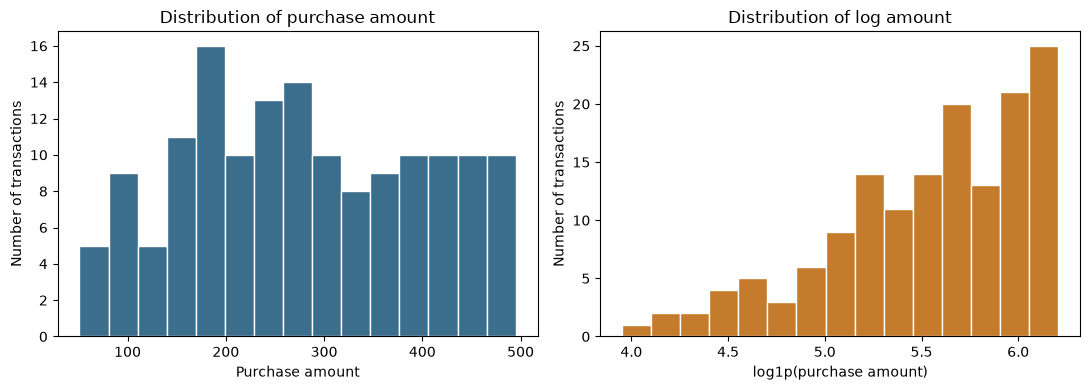

In [19]:
import matplotlib.pyplot as plt
import numpy as np

print("purchase_amount skew:", round(float(merged["purchase_amount"].skew()), 2))
print("log_amount skew:", round(float(merged["log_amount"].skew()), 2))
print("purchase_amount min / median / max:",
      float(merged["purchase_amount"].min()),
      float(merged["purchase_amount"].median()),
      float(merged["purchase_amount"].max()))

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].hist(merged["purchase_amount"], bins=15, color="#3B6D8C", edgecolor="white")
axes[0].set_title("Distribution of purchase amount")
axes[0].set_xlabel("Purchase amount")
axes[0].set_ylabel("Number of transactions")
axes[1].hist(merged["log_amount"], bins=15, color="#C47B2B", edgecolor="white")
axes[1].set_title("Distribution of log amount")
axes[1].set_xlabel("log1p(purchase amount)")
axes[1].set_ylabel("Number of transactions")
fig.tight_layout()
plt.show()


Purchase amount is approximately symmetric. Its skewness is 0.06, the minimum is 51, the median is 274, and the maximum is 495. There is no long right tail. The skewness of `log_amount` is -0.81, so the logarithm compresses the upper end and tilts the distribution left. `log_amount` is retained alongside the raw amount as a rescaled version of the same measurement.

## 8. Outliers by product category

Each category is shown in its own colour. The whiskers mark 1.5 times the interquartile range of that category.

Tukey outliers (beyond 1.5 IQR inside each category)
  Books: 0 of 25; median 282; min 101; max 495
  Clothing: 0 of 28; median 290; min 64; max 490
  Electronics: 0 of 34; median 243; min 51; max 488
  Groceries: 0 of 28; median 252; min 77; max 456
  Sports: 0 of 35; median 292; min 85; max 495


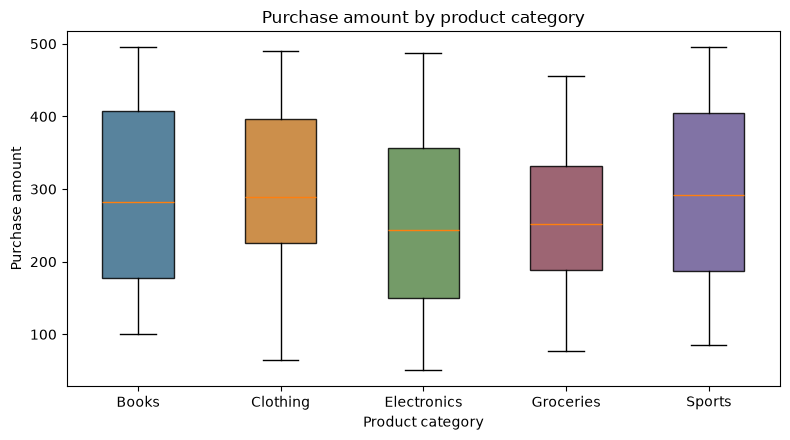

In [22]:
categories = sorted(merged["product_category"].unique())
palette = ["#3B6D8C", "#C47B2B", "#5C8A4D", "#8C4A5A", "#6B5B95"]
groups = [merged.loc[merged["product_category"].eq(cat), "purchase_amount"] for cat in categories]

fig, ax = plt.subplots(figsize=(8, 4.5))
boxes = ax.boxplot(groups, patch_artist=True)
ax.set_xticks(range(1, len(categories) + 1), categories)
for patch, color in zip(boxes["boxes"], palette):
    patch.set_facecolor(color)
    patch.set_alpha(0.85)
ax.set_title("Purchase amount by product category")
ax.set_xlabel("Product category")
ax.set_ylabel("Purchase amount")
fig.tight_layout()
plt.show()

print("Tukey outliers (beyond 1.5 IQR inside each category)")
for cat, series in zip(categories, groups):
    q1, q3 = series.quantile(0.25), series.quantile(0.75)
    fence = 1.5 * (q3 - q1)
    outliers = series[(series < q1 - fence) | (series > q3 + fence)]
    print(f"  {cat}: {len(outliers)} of {len(series)}; "
          f"median {series.median():.0f}; min {series.min():.0f}; max {series.max():.0f}")


No category contains an observation beyond its whiskers. The within-category ranges are wide: Books runs from 101 to 495 and Electronics from 51 to 488, and the other categories are similar. The medians lie between 243 (Electronics) and 292 (Sports), so category does not separate smaller purchases from larger ones.

## 9. Correlations among numeric features

`log_amount` is left off this heatmap because it is a monotone transform of `purchase_amount`, so the two move together by construction. `max_engagement` and `max_interest` are left off for the same reason relative to the means. `interest_x_engagement` is the product of mean interest and mean engagement, so a strong correlation with either parent is expected.


strongest correlations
mean_sentiment     pct_positive             0.91
                   pct_negative            -0.88
mean_interest      interest_x_engagement    0.88
n_social_profiles  n_platforms              0.87
mean_engagement    interest_x_engagement    0.62
pct_positive       pct_negative            -0.60
customer_rating    prior_avg_amount         0.29
n_platforms        mean_engagement          0.26

correlation of each feature with purchase_amount
prior_avg_rating         0.08
interest_x_engagement    0.08
mean_engagement          0.06
mean_interest            0.06
prior_avg_amount        -0.06
pct_positive             0.05
n_social_profiles        0.03
mean_sentiment           0.03
customer_rating          0.03
prior_txn_count          0.01
n_platforms             -0.00
pct_negative             0.00


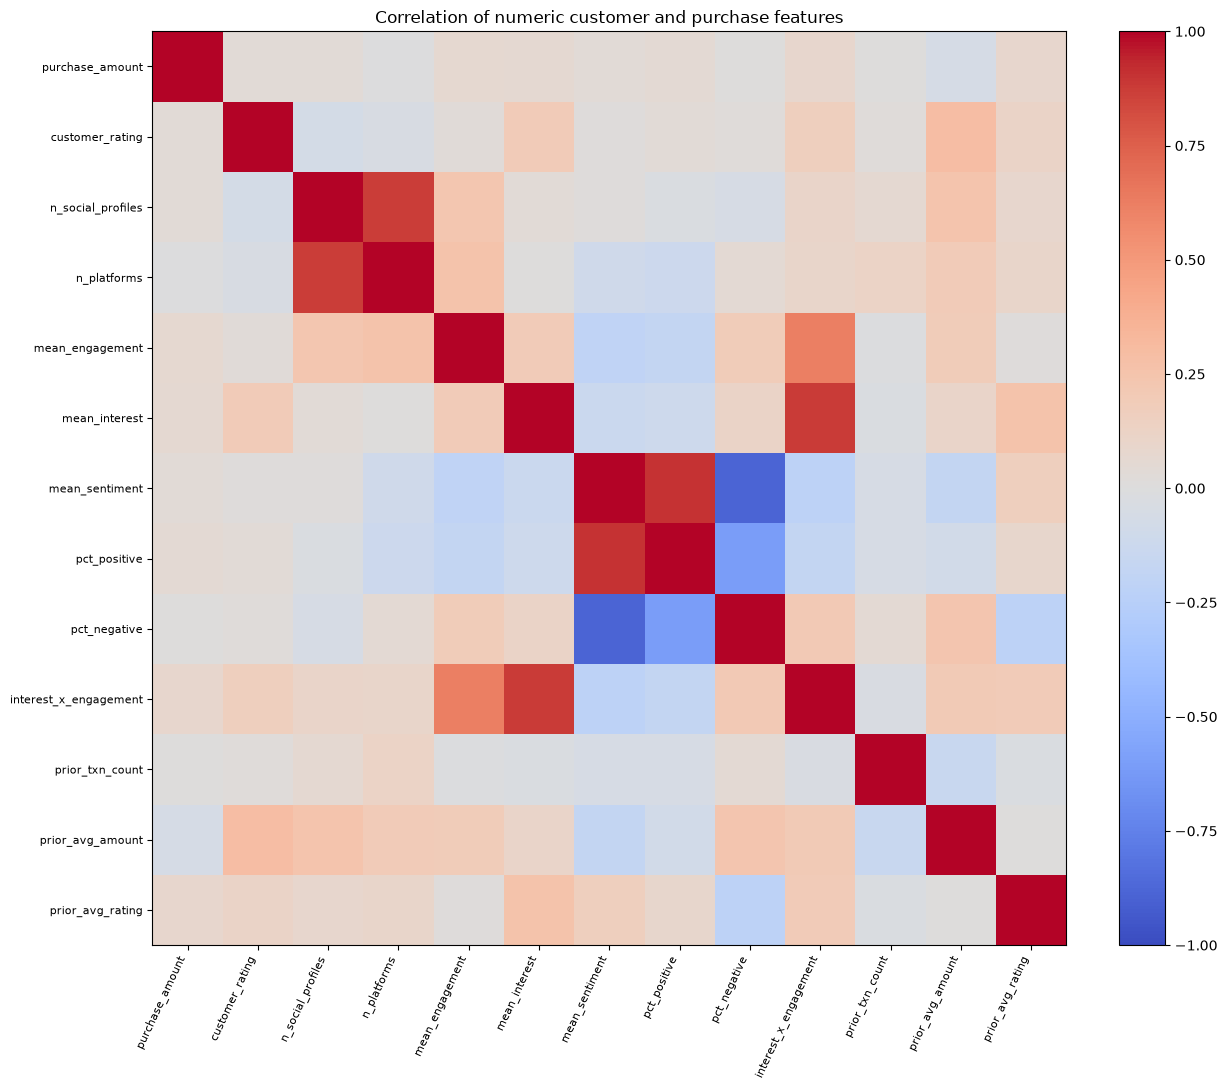

In [25]:
corr_cols = [
    "purchase_amount",
    "customer_rating",
    "n_social_profiles",
    "n_platforms",
    "mean_engagement",
    "mean_interest",
    "mean_sentiment",
    "pct_positive",
    "pct_negative",
    "interest_x_engagement",
    "prior_txn_count",
    "prior_avg_amount",
    "prior_avg_rating",
]
corr = merged[corr_cols].corr()

fig, ax = plt.subplots(figsize=(14, 11))
image = ax.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr_cols)), corr_cols, rotation=65, ha="right", fontsize=8)
ax.set_yticks(range(len(corr_cols)), corr_cols, fontsize=8)
ax.set_title("Correlation of numeric customer and purchase features")
fig.colorbar(image, ax=ax, fraction=0.046, pad=0.04)
fig.tight_layout()
plt.show()

upper = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))
stacked = upper.stack().astype(float)
stacked = stacked.reindex(stacked.abs().sort_values(ascending=False).index)
print("strongest correlations")
print(stacked.head(8).round(2).to_string())
print("\ncorrelation of each feature with purchase_amount")
print(corr["purchase_amount"].drop("purchase_amount").sort_values(key=lambda s: s.abs(), ascending=False).round(2).to_string())


The largest correlations are between columns that were constructed from the same information. Mean sentiment correlates with the share of positive reviews at 0.91 and with the share of negative reviews at -0.88. `interest_x_engagement` correlates with mean interest at 0.88 and with mean engagement at 0.62, which follows from its definition as their product. The number of social profiles correlates with the number of platforms at 0.87.

Purchase amount is weakly related to the other numeric columns. Its largest absolute correlation is 0.08, with `prior_avg_rating`. Engagement, interest, and sentiment do not account for the size of a purchase.

## Conclusion

The transaction and social tables join on a numeric customer identifier once the leading letter is removed from the social id. The outcome, product category, is recorded only on a purchase, so the merge retains every transaction and attaches social features where a profile exists. Twenty-three profiles have no transaction and are excluded. Fourteen customers have transactions and no profile; their 33 transactions remain, with the social fields left missing.

Purchase amounts lie between 51 and 495 and are approximately symmetric. Category does not separate high and low amounts, and no category contains an observation beyond the Tukey whiskers. The strong associations among the numeric social columns follow from how those columns were defined. Purchase amount is effectively uncorrelated with them.

The social aggregates have a further limitation. Profiles carry no timestamp, so the customer-level mean is attached to every purchase by that customer, including purchases that preceded a later review. The prior-purchase features do not have this property, because they are computed from earlier transactions only.